# Worked example

This notebook makes the two figures on the project README: a dispersed
waterfall, and the DM–time plane after FDMT. The pulse has DM 250 and reaches
the bottom of the band (`f_min`) at sample 400. FDMT's time axis is the arrival
time at `f_min`, so the peak should land there.

In [1]:
import numpy as np
from matplotlib import pyplot as plt
from dmtlib.simulate import generate_frb
from dmtlib import FDMT

In [2]:
nchans = 256; f_max = 1440.0; foff = 1.0; tsamp = 1e-3; nsamps = 512
f_min = f_max - nchans*foff

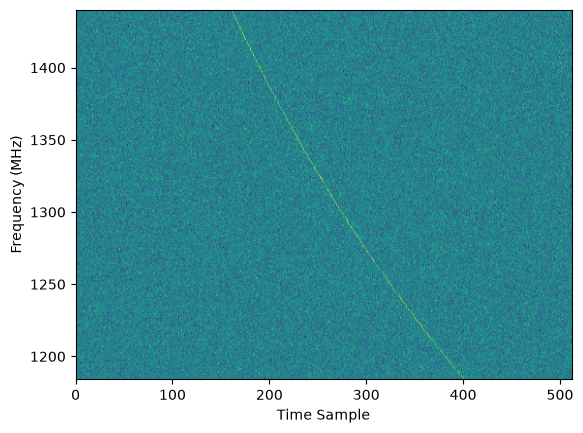

In [3]:
frb = generate_frb(f_min, f_max, nchans, nsamps, tsamp, dm=250, offset=400, amp=20, noise_rms=5, width=1)
plt.imshow(frb, origin='lower', aspect='auto', extent=[0, nsamps, f_min, f_max])
plt.xlabel('Time Sample')
plt.ylabel('Frequency (MHz)')
plt.savefig("../_static/waterfall.png", bbox_inches='tight', dpi=100)

In [4]:
thefdmt = FDMT(f_min, f_max, nchans, nsamps, tsamp, dt_max=512, dt_min=0, dt_step=1, nthreads=8)
print(thefdmt.summary())
dmt_transform = thefdmt.execute(frb.astype(np.float32))

*** FDMT Plan Summary ***
Input: Waterfall Size: (256 x 512; 0.5 MB ), DMT Size: (513 x 512; 1.0 MB )
Plan Memory Usage: 1.0 MB
Largest Level: (393216; 1.5 MB ), History: level-0 (768; 0.0 MB ), tree (146593; 0.6 MB )
Plan Details: {ncoords} ({nchans}x[{ndt_min}..{ndt_max}]) x {nsamps}, {nelements}
Iteration  0:   768 (  256x[    2..    4]) x    512,     393216
Iteration  1:   640 (  128x[    4..    7]) x    512,     327680
Iteration  2:   576 (   64x[    7..   12]) x    512,     294912
Iteration  3:   544 (   32x[   13..   22]) x    512,     278528
Iteration  4:   528 (   16x[   25..   43]) x    512,     270336
Iteration  5:   520 (    8x[   50..   83]) x    512,     266240
Iteration  6:   516 (    4x[  103..  159]) x    512,     264192
Iteration  7:   514 (    2x[  220..  294]) x    512,     263168
Iteration  8:   513 (    1x[  513..  513]) x    512,     262656
********************************************************************************
*** FDMT (cpu) ***
Mode: valid, 8 threads, 

Maximum at t = 401, DM = 250.3 pc/cm^3 (injected: t = 400, DM = 250)


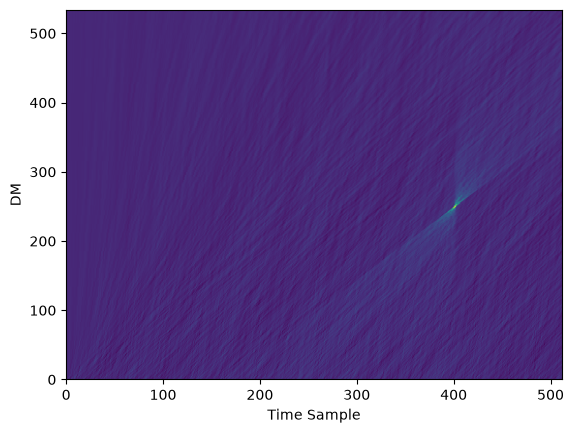

In [5]:
dm_grid = thefdmt.plan.dm_grid_final
plt.imshow(dmt_transform, origin='lower', aspect='auto', extent=[0, nsamps, dm_grid.min(), dm_grid.max()])
idm_max, t_max = np.unravel_index(dmt_transform.argmax(), dmt_transform.shape)
print(f"Maximum at t = {t_max}, DM = {dm_grid[idm_max]:.1f} pc/cm^3 (injected: t = 400, DM = 250)")
plt.xlabel('Time Sample')
plt.ylabel('DM')
plt.savefig("../_static/dmt.png", bbox_inches='tight', dpi=100)